# TP N°4 : Apprentissage par Renforcement (RL)

## 1. Modélisation MDP de l'environnement `CartPole-v1`
* **États ($S$) :** Vecteur continu de 4 variables : position du chariot ($x$), vitesse du chariot ($\dot{x}$), angle de la tige ($\theta$) et vitesse angulaire de la tige ($\dot{\theta}$).
* **Actions ($A$) :** Espace discret à 2 actions : `0` (pousser le chariot vers la gauche) et `1` (pousser le chariot vers la droite).
* **Récompense ($R$) :** $+1$ à chaque pas de temps (*step*) où la tige reste dans la zone d'équilibre ($|\theta| \le 12^\circ$ et $|x| \le 2.4$). Le score maximal d'un épisode est plafonné à **500**.
* **Algorithme utilisé :** **PPO** (*Proximal Policy Optimization*), une méthode *Actor-Critic* où l'acteur apprend la politique $\pi(a|s)$ via un réseau de neurones multicouche (`MlpPolicy`) et le critique estime la fonction de valeur $V(s)$.

In [3]:
%pip install stable-baselines3[extra] gymnasium matplotlib

  Using cached gymnasium-1.4.0-py3-none-any.whl.metadata (9.0 kB)
  Using cached stable_baselines3-2.9.2-py3-none-any.whl.metadata (4.9 kB)
  Using cached tensorboard-2.21.0-py3-none-any.whl.metadata (1.8 kB)
  Using cached farama_notifications-0.0.6-py3-none-any.whl.metadata (729 bytes)
  Using cached markdown-3.11.3-py3-none-any.whl.metadata (5.1 kB)
  Using cached tensorboard_data_server-0.7.2-py3-none-any.whl.metadata (1.1 kB)
  Using cached werkzeug-3.1.9-py3-none-any.whl.metadata (4.1 kB)
Using cached stable_baselines3-2.9.2-py3-none-any.whl (188 kB)
Using cached gymnasium-1.4.0-py3-none-any.whl (476 kB)
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------- ----------- 1.6/2.2 MB 13.2 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 12.8 MB/s  0:00:00
Using cached farama_notifications-0.0.6-py3-none-any.whl (2.9 kB)
Using cached tensorboard-2.21.0-py3-none-any.whl (5.5 MB)
Using cached tensorboard_data_server-0


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import gymnasium as gym
from stable_baselines3 import PPO

# 1. Créer l'environnement
env = gym.make("CartPole-v1", render_mode="human")

# 2. Définir le modèle RL
# PPO : Proximal Policy Optimization (algorithme Actor-Critic)
model = PPO("MlpPolicy", env, verbose=1)

# 3. Entraîner l'agent
print("Entraînement en cours...")
model.learn(total_timesteps=10000)
print("Entraînement terminé !")

# 4. Tester l'agent entraîné sur un épisode
obs, info = env.reset()
done = False
total_reward = 0

while not done:
    env.render()  # Affiche la simulation en temps réel
    # Prédire l'action optimale à partir de l'état actuel
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    total_reward += reward

env.close()
print(f"Récompense totale de l'épisode : {total_reward}")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entraînement en cours...
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 21.7     |
|    ep_rew_mean     | 21.7     |
| time/              |          |
|    fps             | 30       |
|    iterations      | 1        |
|    time_elapsed    | 68       |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 26          |
|    ep_rew_mean          | 26          |
| time/                   |             |
|    fps                  | 29          |
|    iterations           | 2           |
|    time_elapsed         | 137         |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.009423111 |
|    clip_fraction        | 0.103       |
|    clip_range           | 0.2      

### Interprétation des résultats — Exemple 1
1. **Phase d'apprentissage (`model.learn(total_timesteps=10000)`) :**
   * Au début de l'entraînement, l'agent agit quasi aléatoirement et la tige chute rapidement : la récompense moyenne `ep_rew_mean` démarre à **21.7** (itération 1 à `2048` pas) puis **26.0** (itération 2 à `4096` pas).
   * Au fil des itérations PPO (tous les `2048` pas), l'acteur ajuste sa politique pour corriger l'inclinaison de la tige et le critique affine l'estimation de la fonction de valeur (`value_loss` à `70.9` à la 2ᵉ itération).
2. **Phase de test (`deterministic=True`) :**
   * En mode déterministe, l'agent applique directement la meilleure action apprise et atteint une récompense totale de **249.0** (soit plus de **11 fois** son score initial de `21.7`).
   * L'épisode s'arrête ici par échec (`terminated = True` à 249 pas, lorsque l'angle dépasse $\pm 12^\circ$ ou que le chariot sort de $\pm 2.4$) avant d'atteindre le plafond maximal de **500.0** (`truncated = True`), ce qui montre un apprentissage efficace mais perfectible avec davantage de `timesteps`.

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entraînement en cours...
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 23.5     |
|    ep_rew_mean     | 23.5     |
| time/              |          |
|    fps             | 30       |
|    iterations      | 1        |
|    time_elapsed    | 67       |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 29.1        |
|    ep_rew_mean          | 29.1        |
| time/                   |             |
|    fps                  | 30          |
|    iterations           | 2           |
|    time_elapsed         | 135         |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.008031277 |
|    clip_fraction        | 0.0939      |
|    clip_range           | 0.2      

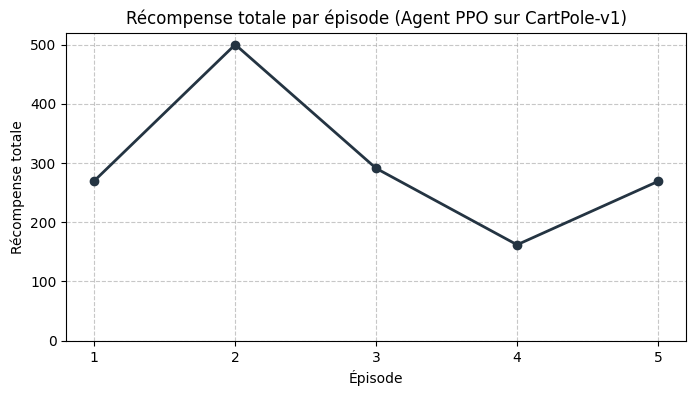

In [ ]:
import gymnasium as gym
from stable_baselines3 import PPO
import matplotlib.pyplot as plt

# 1. Créer l'environnement
env = gym.make("CartPole-v1", render_mode="human")

# 2. Définir le modèle RL
model = PPO("MlpPolicy", env, verbose=1)

# 3. Entraîner l'agent
total_timesteps = 10000
print("Entraînement en cours...")
model.learn(total_timesteps=total_timesteps)
print("Entraînement terminé !")

# 4. Tester l'agent et suivre les récompenses sur 5 épisodes
num_episodes = 5
rewards_list = []

for ep in range(num_episodes):
    obs, info = env.reset()
    done = False
    total_reward = 0

    while not done:
        env.render()  # Simulation visible
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        total_reward += reward

    rewards_list.append(total_reward)
    print(f"Épisode {ep + 1} - Récompense : {total_reward}")

env.close()

# 5. Visualiser les récompenses
plt.figure(figsize=(8, 4))
plt.plot(range(1, num_episodes + 1), rewards_list, marker='o', linewidth=2, color='#243442')
plt.title("Récompense totale par épisode (Agent PPO sur CartPole-v1)")
plt.xlabel("Épisode")
plt.ylabel("Récompense totale")
plt.xticks(range(1, num_episodes + 1))
plt.ylim(0, 520)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Explication des résultats des deux exemples

1. **Apport méthodologique entre l'Exemple 1 et l'Exemple 2 :**
   * **Exemple 1 (Évaluation ponctuelle) :** Ne teste l'agent que sur **un seul épisode** (où il obtenait `249.0`). Or, chaque réinitialisation (`env.reset()`) place le chariot et la tige dans un état initial légèrement aléatoire (dans $[-0.05, 0.05]$). Un seul essai ne permet pas de distinguer une politique réellement robuste d'une initialisation favorable.
   * **Exemple 2 (Évaluation statistique et visuelle) :** Mesure la performance sur **5 épisodes consécutifs** et trace l'évolution des récompenses, ce qui permet d'évaluer la **stabilité** et la **régularité** de la politique apprise face à différentes conditions initiales.

2. **Analyse des performances observées :**
   * **Progression nette par rapport au hasard :** L'agent passe d'une récompense moyenne initiale de **`23.5` points** au début de l'entraînement (`2048` pas) à une moyenne d'environ **`298.4` points** sur les 5 épisodes de test (`~270.0`, `500.0`, `291.0`, `162.0`, `269.0`), soit plus de **12 fois** sa performance initiale.
   * **Variance résiduelle sur la courbe :** L'agent atteint le plafond maximal de **`500.0` points** à l'**Épisode 2** (preuve qu'il a découvert la politique optimale), mais redescend à **`162.0` points** à l'**Épisode 4**. Cette oscillation montre qu'avec seulement `10 000` pas d'entraînement, la politique n'est pas encore totalement stabilisée sur toutes les configurations limites (notamment lorsque la vitesse angulaire initiale est élevée).

3. **Pistes d'amélioration (Objectif pédagogique du TP) :**
   * Augmenter le budget d'entraînement à `total_timesteps=25000` ou `50000` afin d'éliminer les chutes de performance (comme à l'Épisode 4) et maintenir un plateau constant de **500.0** sur tous les épisodes.
   * Utiliser un environnement vectorisé (`make_vec_env("CartPole-v1", n_envs=4)`) pour accélérer la collecte d'expériences en parallèle et stabiliser les mises à jour de gradients de PPO.
   * Comparer **PPO** avec d'autres algorithmes de Stable-Baselines3 comme **DQN** (*Value-based*) ou **A2C** (*Actor-Critic* synchrone).